In [1]:
import pandas as pd
import numpy as py
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker


data_path = "./data/"

csv_files = glob.glob(data_path + "*.csv")

dataframe = {}

for file in csv_files:
    name = os.path.basename(file).replace(".csv","")
    dataframe[name] = pd.read_csv(file)

In [2]:
orders = dataframe["olist_orders_dataset"]

print("订单表行列数",orders.shape)
orders.head()

订单表行列数 (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
#查看日期时间数据类型
print(orders["order_purchase_timestamp"].dtype)

print(orders["order_purchase_timestamp"].dtypes)

str
str


In [4]:
#将字符串（str）转化为时间格式（datatime）
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)
print(orders["order_purchase_timestamp"].dtype)

datetime64[us]


In [5]:
#提取年月；.dt是pandas开放的时间窗口
orders["order_year"] = orders["order_purchase_timestamp"].dt.year
orders["order_month"] = orders["order_purchase_timestamp"].dt.month
print(orders[[
    "order_purchase_timestamp",
    "order_year",
    "order_month",
]].head())

  order_purchase_timestamp  order_year  order_month
0      2017-10-02 10:56:33        2017           10
1      2018-07-24 20:41:37        2018            7
2      2018-08-08 08:38:49        2018            8
3      2017-11-18 19:28:06        2017           11
4      2018-02-13 21:18:39        2018            2


In [6]:
#统计每月的订单数(因为2017和2018的一月份都是一月份但事实年不同，所以也要根据年进行分组)
monthly_orders = orders.groupby(
    ["order_year", "order_month"]
)["order_id"].count()

In [7]:
monthly_orders

order_year  order_month
2016        9                 4
            10              324
            12                1
2017        1               800
            2              1780
            3              2682
            4              2404
            5              3700
            6              3245
            7              4026
            8              4331
            9              4285
            10             4631
            11             7544
            12             5673
2018        1              7269
            2              6728
            3              7211
            4              6939
            5              6873
            6              6167
            7              6292
            8              6512
            9                16
            10                4
Name: order_id, dtype: int64

In [8]:
#统计每月订单数
monthly_orders = monthly_orders.reset_index()
monthly_orders


,order_year,order_month,order_id
0,2016,9,4
1,2016,10,324
2,2016,12,1
3,2017,1,800
4,2017,2,1780
5,2017,3,2682
6,2017,4,2404
7,2017,5,3700
8,2017,6,3245
9,2017,7,4026


In [9]:
#查看最高订单数月份
a = monthly_orders.sort_values(
    by="order_id",
ascending=False
)
print(a)

    order_year  order_month  order_id
13        2017           11      7544
15        2018            1      7269
17        2018            3      7211
18        2018            4      6939
19        2018            5      6873
16        2018            2      6728
22        2018            8      6512
21        2018            7      6292
20        2018            6      6167
14        2017           12      5673
12        2017           10      4631
10        2017            8      4331
11        2017            9      4285
9         2017            7      4026
7         2017            5      3700
8         2017            6      3245
5         2017            3      2682
6         2017            4      2404
4         2017            2      1780
3         2017            1       800
1         2016           10       324
23        2018            9        16
0         2016            9         4
24        2018           10         4
2         2016           12         1


In [10]:
#最高订单量月份在2017年的11月，但2016年的月份显示较少，可能数据不完整；包括18年9，10月份订单明显偏低，是否也是订单数据不完整？18年的1到8月订单维持在较高水平

In [11]:
#为了更好的分析，需要将日期进行统一化，创建年月字段;由于是统计月份，所以以一号作为基准
monthly_orders["order_ym"] = pd.to_datetime(
    monthly_orders["order_year"].astype(str) + "-" + monthly_orders["order_month"].astype(str)
)
monthly_orders.head()

,order_year,order_month,order_id,order_ym
0,2016,9,4,2016-09-01
1,2016,10,324,2016-10-01
2,2016,12,1,2016-12-01
3,2017,1,800,2017-01-01
4,2017,2,1780,2017-02-01


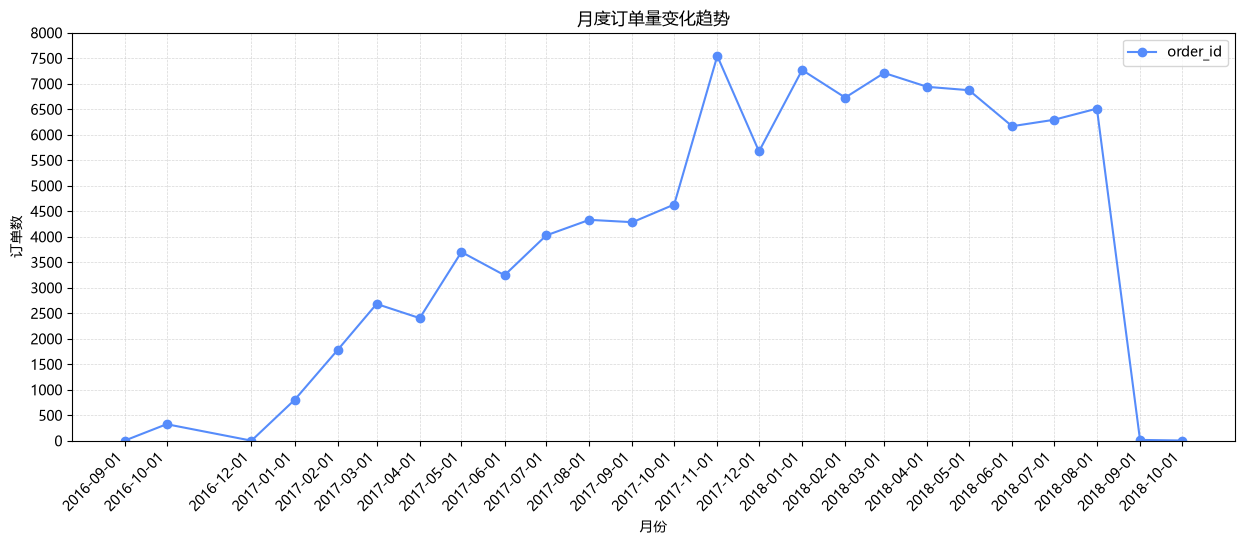

In [12]:
#绘制折线图
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
monthly_orders.plot(
    x="order_ym",
    y="order_id",
    kind="line",
    marker="o",
    figsize = (15,6)
)
plt.ylim(0,8000)
plt.yticks(range(0,8001,500))
plt.title("月度订单量变化趋势")
plt.xlabel("月份")
plt.ylabel("订单数")
plt.xticks(
    monthly_orders["order_ym"],
    rotation=45)
plt.grid(axis="both",linestyle="--",alpha=0.5)
plt.show()

In [13]:
#业务发现：1.整体呈上升趋势；2.2017年达到顶峰，结合之前数据为7544笔；3.在18年1至8月保持较高水平；4.9至10月订单不完整，不作为参考证据

In [14]:
#月度销售额分析
items = dataframe["olist_order_items_dataset"]
print("商品明细表行列参数",items.shape)
items.head()

商品明细表行列参数 (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [15]:
#合并商品订单和商品明细表;因为是统计商品月度销售额，需要保留商品明细，所以需要为销售额补充购买时间，所以items为左表
order_items_data = pd.merge(
    items,
    orders,
    on = "order_id",
    how="left"
)
print("合并前数据行数",len(items))
print("合并后数据行数",len(order_items_data))

合并前数据行数 112650
合并后数据行数 112650


In [16]:
#提取订单年月
order_items_data["order_ym"] = (
    order_items_data["order_purchase_timestamp"].dt.to_period("M")
)
print(order_items_data[[
    "order_id",
    "order_purchase_timestamp",
    "order_ym",
    "price"
]].head())

                           order_id order_purchase_timestamp order_ym   price
0  00010242fe8c5a6d1ba2dd792cb16214      2017-09-13 08:59:02  2017-09   58.90
1  00018f77f2f0320c557190d7a144bdd3      2017-04-26 10:53:06  2017-04  239.90
2  000229ec398224ef6ca0657da4fc703e      2018-01-14 14:33:31  2018-01  199.00
3  00024acbcdf0a6daa1e931b038114c75      2018-08-08 10:00:35  2018-08   12.99
4  00042b26cf59d7ce69dfabb4e55b4fd9      2017-02-04 13:57:51  2017-02  199.90


In [17]:
#统计每月的销售额
monthly_sales = (order_items_data.groupby(
    "order_ym"
)["price"].sum())
monthly_sales

order_ym
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Freq: M, Name: price, dtype: float64

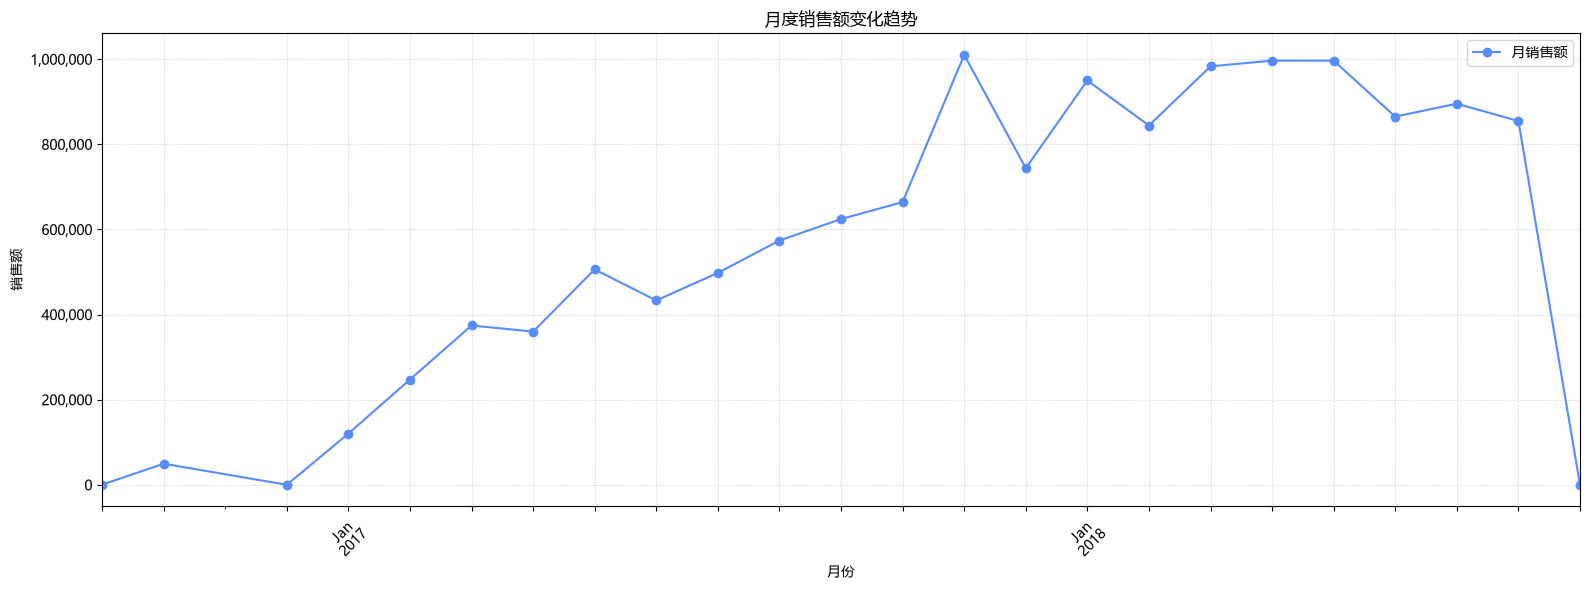

In [21]:
#绘制图表
monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(16,6),
    label="月销售额"
)
plt.title("月度销售额变化趋势")
plt.xlabel("月份")
plt.ylabel("销售额")
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.xticks(monthly_sales.index,rotation=45)
plt.grid(axis="both",linestyle="--",alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
#整理合并月度数据
#整理月度订单量
monthly_orders_compare = monthly_orders[["order_ym","order_id"]].copy()
#将年月日统一转化为月份周期
monthly_orders_compare["order_ym"] = (
    monthly_orders_compare["order_ym"].dt.to_period("M")
)
#月度销售额
monthly_sales_compare = monthly_sales.rename("sales_amount").reset_index()
#合并
monthly_analysis = pd.merge(
    monthly_orders_compare,
    monthly_sales_compare,
    on = "order_ym",
    how="outer"#保留两表所有月份
)
print(monthly_analysis)

   order_ym  order_id  sales_amount
0   2016-09         4        267.36
1   2016-10       324      49507.66
2   2016-12         1         10.90
3   2017-01       800     120312.87
4   2017-02      1780     247303.02
5   2017-03      2682     374344.30
6   2017-04      2404     359927.23
7   2017-05      3700     506071.14
8   2017-06      3245     433038.60
9   2017-07      4026     498031.48
10  2017-08      4331     573971.68
11  2017-09      4285     624401.69
12  2017-10      4631     664219.43
13  2017-11      7544    1010271.37
14  2017-12      5673     743914.17
15  2018-01      7269     950030.36
16  2018-02      6728     844178.71
17  2018-03      7211     983213.44
18  2018-04      6939     996647.75
19  2018-05      6873     996517.68
20  2018-06      6167     865124.31
21  2018-07      6292     895507.22
22  2018-08      6512     854686.33
23  2018-09        16        145.00
24  2018-10         4           NaN


In [25]:
#计算月均订单销售额
#销售额/月订单数
monthly_analysis["AOV"] = (monthly_analysis["sales_amount"] / monthly_analysis["order_id"]).round(2)
print(monthly_analysis)

   order_ym  order_id  sales_amount     AOV
0   2016-09         4        267.36   66.84
1   2016-10       324      49507.66  152.80
2   2016-12         1         10.90   10.90
3   2017-01       800     120312.87  150.39
4   2017-02      1780     247303.02  138.93
5   2017-03      2682     374344.30  139.58
6   2017-04      2404     359927.23  149.72
7   2017-05      3700     506071.14  136.78
8   2017-06      3245     433038.60  133.45
9   2017-07      4026     498031.48  123.70
10  2017-08      4331     573971.68  132.53
11  2017-09      4285     624401.69  145.72
12  2017-10      4631     664219.43  143.43
13  2017-11      7544    1010271.37  133.92
14  2017-12      5673     743914.17  131.13
15  2018-01      7269     950030.36  130.70
16  2018-02      6728     844178.71  125.47
17  2018-03      7211     983213.44  136.35
18  2018-04      6939     996647.75  143.63
19  2018-05      6873     996517.68  144.99
20  2018-06      6167     865124.31  140.28
21  2018-07      6292     895507

In [28]:
AOV_top = monthly_analysis.sort_values(
    by = "AOV",
    ascending=False
)
AOV_top
#2017.11订单量7544，销售额1010271.37，AOV133.92，说明订单量多所以销售额高；2018.4订单量6939，销售额996647.45AOV143.63，说明销售额高不是订单量多，而是平均销售额高

,order_ym,order_id,sales_amount,AOV
1,2016-10,324,49507.66,152.80
3,2017-01,800,120312.87,150.39
6,2017-04,2404,359927.23,149.72
11,2017-09,4285,624401.69,145.72
19,2018-05,6873,996517.68,144.99
18,2018-04,6939,996647.75,143.63
12,2017-10,4631,664219.43,143.43
21,2018-07,6292,895507.22,142.32
20,2018-06,6167,865124.31,140.28
5,2017-03,2682,374344.30,139.58


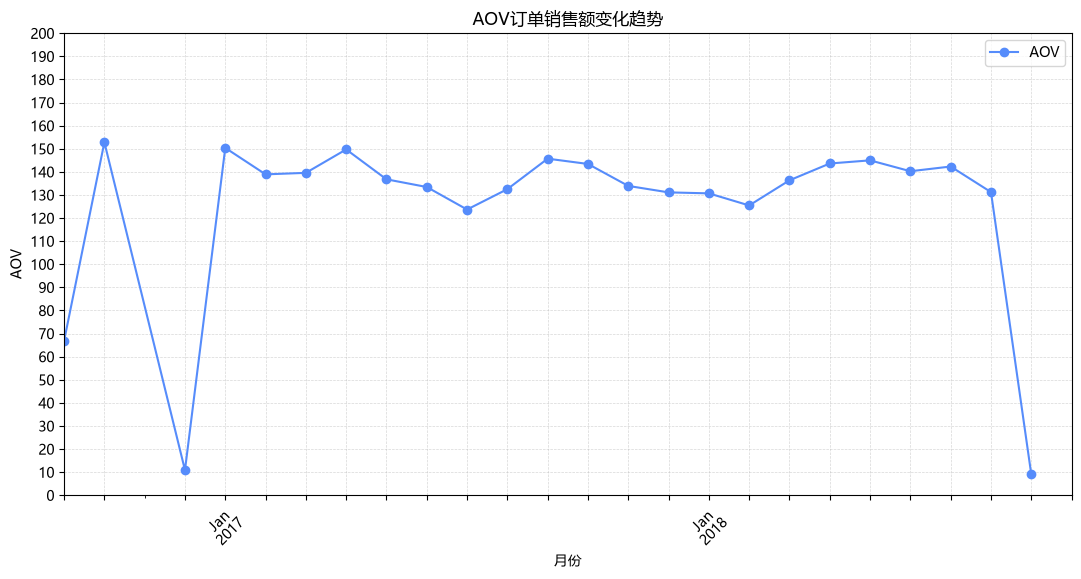

In [43]:
monthly_analysis.plot(
    kind="line",
    marker="o",
    x="order_ym",
    y="AOV",
    figsize=(13,6),
    label="AOV",
)
plt.title("AOV订单销售额变化趋势")
plt.xlabel("月份")
plt.ylabel("AOV")
plt.ylim(0,200)
plt.xticks(
    monthly_analysis["order_ym"],
    rotation=45,
)
plt.yticks(range(0,201,10))
plt.grid(axis="both",linestyle="--",alpha=0.5)
plt.legend()
plt.show()

In [42]:
#整体AOV趋于平稳，说明订单量和平均销售额并不完全同步；所以销售额的增长可能来自订单的数量增加

,order_ym,order_id,sales_amount,AOV
0,2016-09,4,267.36,66.84
1,2016-10,324,49507.66,152.80
2,2016-12,1,10.90,10.90
3,2017-01,800,120312.87,150.39
4,2017-02,1780,247303.02,138.93
5,2017-03,2682,374344.30,139.58
6,2017-04,2404,359927.23,149.72
7,2017-05,3700,506071.14,136.78
8,2017-06,3245,433038.60,133.45
9,2017-07,4026,498031.48,123.70
